# Getting started with v3

v3 simulates cryo-EM particle images. You give it the 3-D structure of a molecule, and it returns **synthetic** particle images that resemble the images of an **experimental** single-particle data set: the molecule seen from random directions, blurred by the microscope, surrounded by neighbouring objects, and buried in noise.

* **Part 1** starts from a single PDB file and makes ten images with the default settings, explaining every step.
* **Part 2** brings the simulation closer to one experimental data set: several conformations of the molecule, the noise spectrum measured on experimental particles, and a prior of your own.

Run the cells from top to bottom, from the repository folder. The packages are listed in `requirements.txt`: PyTorch, NumPy, MDAnalysis (reads PDB files), mrcfile (reads particle files) and matplotlib. A GPU is used if there is one; a CPU works too.

## The idea: φ → θ → image

Every synthetic image is made from a short list of settings: which conformation of the molecule, from which direction it is seen, how strongly the microscope blurs it, how much noise is added, and so on. v3 keeps three objects apart:

| object | size | what it describes | example |
|---|---|---|---|
| **φ**, the prior | 44 numbers | how the settings vary across a whole data set | "the defocus lies between 0.06 and 5.6 µm" |
| **θ**, the settings | 156 numbers per image | the settings of one image, drawn at random from φ | "this image has a defocus of 1.7 µm" |
| **image** | N × N pixels | the picture made from θ | |

Two functions connect them: **`sample_theta`** draws θ from φ, and **`render`** turns θ into images.

In [8]:
import copy

import matplotlib.pyplot as plt
import torch

import v3_core as v3

device = "cuda" if torch.cuda.is_available() else "cpu"
print("running on", device)


def show(images, titles=None, cols=5, size=2.3):
    """Plot a stack of images in a grid."""
    images = [im.detach().cpu() for im in images]
    rows = (len(images) + cols - 1) // cols
    lines = max((t.count("\n") + 1 for t in titles), default=0) if titles else 0
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, rows * (size + 0.18 * lines) + 0.2), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images):
            ax.imshow(images[i], cmap="gray")
            if titles:
                ax.set_title(titles[i], fontsize=8)
    plt.tight_layout()
    plt.show()

running on cuda


---
# Part 1 — Ten images from one PDB file

## 1.1 The molecule

We start from PDB entry **5IRX** (`data/pdb/5irx.pdb`): the TRPV1 ion channel, built from four identical subunits, with the spider toxin DkTx and the ligand RTX bound, in a lipid nanodisc (Gao *et al.*, *Nature* 2016). It is the structure deposited for the experimental data set EMPIAR-10059, whose particles we use in Part 2.

v3 does not draw every atom. It keeps **one point per residue**, the C-alpha atom of each amino acid (for nucleic acids, use the phosphorus atom: `atom_selection="name P"`), and later puts a small Gaussian blob, a **bead**, on each point. `load_bank` reads every PDB file in a folder, centres it, and keeps the selected atoms. Each file becomes one **conformer**; with one file, the bank holds one conformer.

bank shape: (1, 1, 3, 1726) = (conformers, representatives, x/y/z, beads)
1726 beads; the molecule spans 107 x 107 x 95 Angstrom


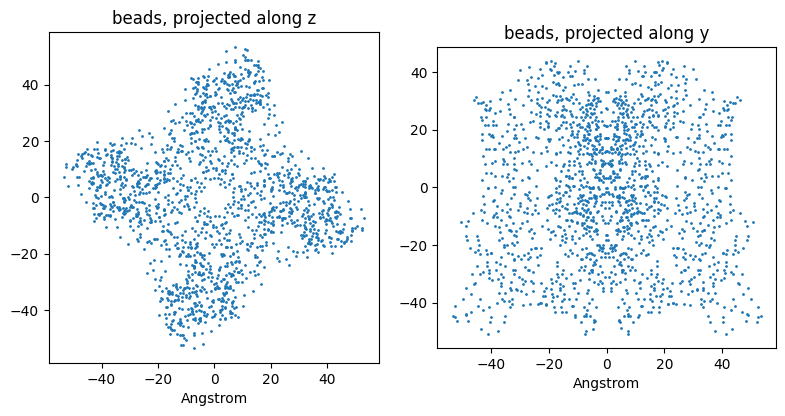

In [9]:
bank = v3.load_bank("data/pdb", device=device)       # every .pdb file in the folder becomes one conformer
print("bank shape:", tuple(bank.shape), "= (conformers, representatives, x/y/z, beads)")

beads = bank[0, 0].cpu()                                # (3, beads), in Angstrom, centred at 0
size = (beads.max(dim=1).values - beads.min(dim=1).values).tolist()
print(f"{beads.shape[1]} beads; the molecule spans {size[0]:.0f} x {size[1]:.0f} x {size[2]:.0f} Angstrom")

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].scatter(beads[0], beads[1], s=1); ax[0].set_title("beads, projected along z")
ax[1].scatter(beads[0], beads[2], s=1); ax[1].set_title("beads, projected along y")
for a in ax:
    a.set_aspect("equal"); a.set_xlabel("Angstrom")
plt.tight_layout(); plt.show()

The second axis of the bank ("representatives") can hold several models of the same conformer; here it is 1.

## 1.2 The box

A particle image is a small square cut out of a micrograph. **`RenderShape`** holds the fixed facts of that square:

* `num_pixels`, the box size N in pixels;
* `pixel_size`, how many Angstrom one pixel covers.

We use the box of the experimental TRPV1 particles: 192 pixels of 1.345 Å, 258 Å across, wide enough for the molecule and its surroundings.

`RenderShape` also says where the **noise spectrum** comes from, that is, how strong the noise is at each spatial scale. We give none here, so v3 uses an average spectrum measured on several experimental data sets (`data/global_average_empirical_psd.pt`). Part 2 measures the spectrum of one data set.

In [10]:
shape = v3.RenderShape(num_pixels=192, pixel_size=1.345)
print(f"box: {shape.num_pixels} pixels x {shape.pixel_size} A = {shape.box_A:.0f} A")

box: 192 pixels x 1.345 A = 258 A


## 1.3 The prior φ

The prior describes a whole data set. **`v3.DEFAULT_PRIOR`** is a dictionary of 25 entries holding 44 numbers, in physical units:

* a range `[lo, hi]` means "each image draws a value uniformly between lo and hi";
* a single number between 0 and 1 is a probability.

The entries come in four groups, one for each kind of thing an image contains:

* **optics**: bead width, defocus, B-factor, signal-to-noise ratio;
* **noise**: how white, coloured and shot noise are mixed;
* **clutter**: how many objects surround the molecule, and what they are;
* **band**: how often an edge band appears, and how deep it is.

The table is printed from the library itself, so it always matches the code.

In [11]:
import re

for slot in v3.PHI_LAYOUT:
    meaning = re.split(r"(?<!Eq)\. ", slot.doc)[0].rstrip(".")      # the first sentence of the description
    print(f"{slot.group:8s} {slot.name:20s} {str(v3.DEFAULT_PRIOR[slot.name]):40s} {meaning}")

optics   SIGMA                [0.261, 2.41]                            Range of the bead width sigma, in Angstrom
optics   DEFOCUS              [0.0551, 5.62]                           Range of the defocus, in micrometres
optics   B_FACTOR             [0.0871, 129.0]                          Range of the CTF B-factor, in Angstrom^2
optics   SNR                  [-5.8, -1.5]                             Range of log10(SNR)
noise    MIX_RANGE_gaussian   [0.0, 0.784]                             Range of the white-noise weight
noise    MIX_RANGE_fft        [0.0, 0.956]                             Range of the coloured-noise weight
noise    MIX_RANGE_poisson    [0.0, 0.498]                             Range of the shot-noise weight
noise    CONC_fft             8.49                                     Pushes the coloured-noise weight towards the top of its range: w = lo + (hi - lo) * u ** (1 / CONC_fft), with u uniform in [0, 1]
noise    WHITE_FRAC_fft       0.205                            

`pack_phi` turns the dictionary into the 44 numbers v3 works with. They are stored in a form in which any 44 numbers make a valid prior, so you never need to read or edit them: to change the prior, change the dictionary and pack it again (Part 2).

In [12]:
phi = v3.pack_phi(v3.DEFAULT_PRIOR, device=device)
print("phi:", tuple(phi.shape))

phi: (44,)


## 1.4 The settings θ of ten images

**`sample_theta(phi, n, seed, bank, shape)`** draws the settings of `n` images. The **seed** makes the draw repeatable: the same seed gives the same θ. Each image gets 156 numbers, and **`unpack_theta`** gives them names. The most important ones:

| name | meaning |
|---|---|
| `conformer_idx` | which conformer of the bank (always 0 here) |
| `quaternion` | the viewing direction: 4 numbers describing a rotation, uniform over all directions |
| `sigma` | bead width, Å |
| `defocus` | µm |
| `b_factor` | Å², how strongly fine detail fades |
| `log10_snr` | log10 of the signal-to-noise ratio |
| `noise_regime` | coloured noise only, white noise only, or a mix of white, coloured and shot noise |
| `cl_present` | which of the 5 clutter slots hold an object |
| `band_present` | whether the image has an edge band |

In [7]:
theta = v3.sample_theta(phi, 10, seed=0, bank=bank, cfg=shape)
print("theta:", tuple(theta.shape))

f = v3.unpack_theta(theta)
noise_kind = {0: "coloured", 1: "white", 2: "mixed"}
print(f"{'image':>5} {'sigma A':>8} {'defocus um':>10} {'B A^2':>6} {'log10 SNR':>9} {'noise':>8} {'objects':>7} {'band':>4}")
for i in range(10):
    print(f"{i:5d} {f['sigma'][i].item():8.2f} {f['defocus'][i].item():10.2f} {f['b_factor'][i].item():6.1f} "
          f"{f['log10_snr'][i].item():9.2f} {noise_kind[int(f['noise_regime'][i])]:>8} "
          f"{int(f['cl_present'][i].sum()):7d} {'yes' if f['band_present'][i] else 'no':>4}")

theta: (10, 156)
image  sigma A defocus um  B A^2 log10 SNR    noise objects band
    0     1.55       0.74   48.5     -4.19 coloured       2   no
    1     0.40       0.69   67.5     -4.70    white       1   no
    2     1.43       2.68   73.9     -4.40 coloured       4   no
    3     0.66       3.26   79.8     -5.41    mixed       1   no
    4     0.33       1.70   89.8     -4.11    mixed       1   no
    5     2.29       4.49   68.4     -3.19    mixed       0   no
    6     2.15       1.14   33.1     -5.05 coloured       0   no
    7     0.26       5.36   95.0     -3.76    white       1   no
    8     1.54       4.74    2.7     -2.11 coloured       1   no
    9     1.15       0.49   26.3     -3.87 coloured       0   no


## 1.5 Render the images

**`render(theta, bank, shape)`** makes one image per row of θ.

images: (10, 192, 192)


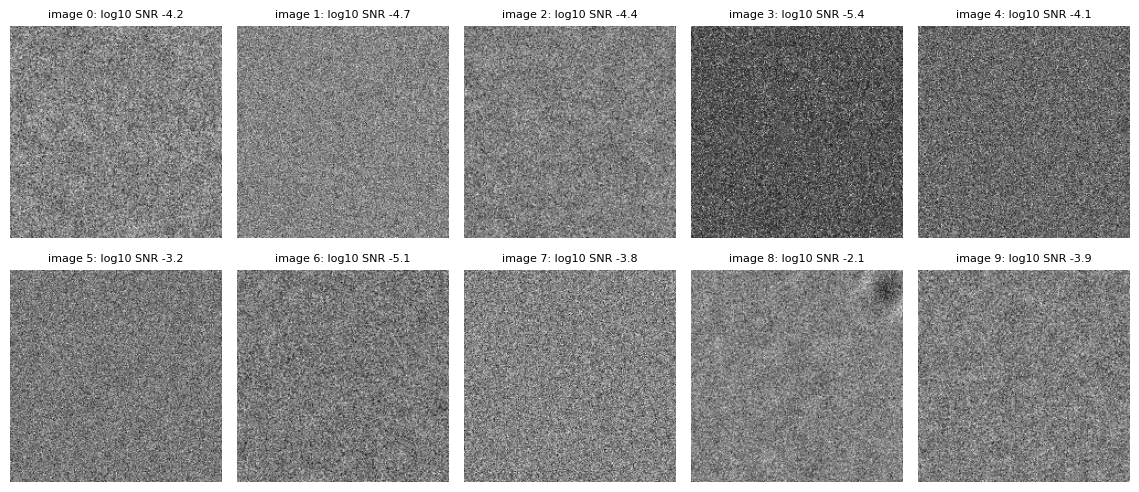

In [13]:
images = v3.render(theta, bank, shape)
print("images:", tuple(images.shape))
show(images, [f"image {i}: log10 SNR {f['log10_snr'][i].item():.1f}" for i in range(10)])

Can you see the molecule? Mostly not, and that is the point. In experimental data the signal-to-noise ratio (SNR) of a single particle image is far below 1. The default prior draws log10 SNR between −5.8 and −1.5: the noise variance is 30 to 600 000 times the signal variance. Finally every image is shifted and scaled to mean 0 and standard deviation 1, as particle images usually are before analysis.

The next sections take one image apart.

## 1.6 Inside one image: switch its parts off

θ is just numbers, so you can edit it and render again. The helper below copies one row of θ, applies a list of edits, and renders every edited copy. We pick an image that has clutter around it, and switch off first the noise (log10 SNR = 3 leaves almost none), then the clutter.

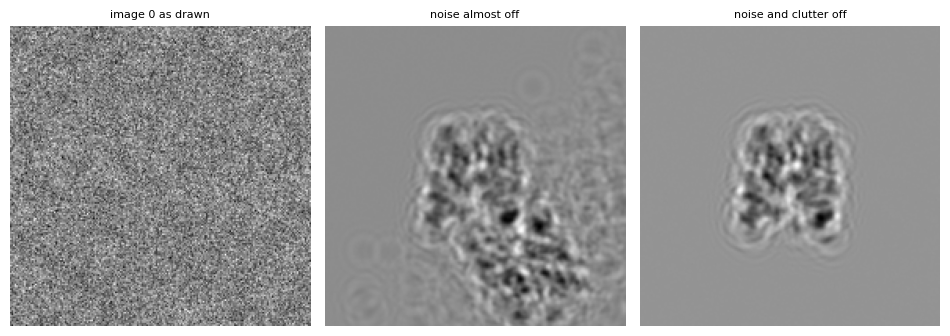

In [14]:
def variants(i, edits):
    """Render image i of theta again, once per dictionary of edited settings."""
    t = theta[i:i + 1].repeat(len(edits), 1)          # copies of row i
    g = v3.unpack_theta(t)
    for row, edit in enumerate(edits):
        for name, value in edit.items():
            g[name][row] = value
    return v3.render(v3.pack_theta(g), bank, shape)


k = next(i for i in range(10) if f["cl_present"][i].sum() > 0)      # the first image with clutter
quiet = {"log10_snr": 3.0}                                            # almost no noise
show(variants(k, [{}, quiet, {**quiet, "cl_present": 0.0}]),
     [f"image {k} as drawn", "noise almost off", "noise and clutter off"], cols=3, size=3.2)

What remains in the last panel is the molecule alone, after the microscope blur. The **clutter** that was around it stands in for what experimental particle boxes also contain: neighbouring copies of the molecule, broken-off pieces of it, and random point clouds playing the part of debris, detergent or ice contamination. Some objects sit partly outside the box.

One detail: v3 sets the noise level from the molecule alone, before the clutter is added. The SNR therefore always describes the molecule, however much clutter surrounds it.

## 1.7 The edge band

Some experimental particles lie at the border of their micrograph. Extraction software then fills the part of the box that falls outside the micrograph by repeating the last row of pixels, which leaves a **band** of identical lines along one edge. v3 reproduces this in a fraction of the images (`barcode_prob` in the prior). To see one, we add a band by hand: θ stores whether there is a band, its depth as a fraction of the box, and its side (0 top, 1 bottom, 2 left, 3 right, also stored as four 0/1 numbers).

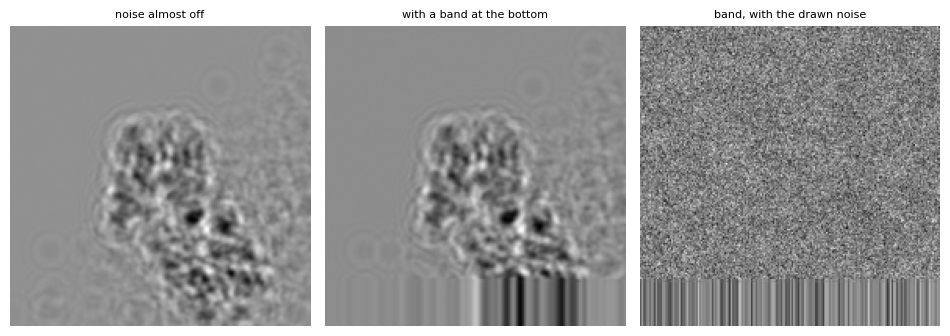

In [15]:
band = {"band_present": 1.0, "band_width_frac": 0.15, "band_side": 1.0,
        "band_side_onehot": torch.tensor([0.0, 1.0, 0.0, 0.0], device=device)}
show(variants(k, [quiet, {**quiet, **band}, band]),
     ["noise almost off", "with a band at the bottom", "band, with the drawn noise"], cols=3, size=3.2)

## 1.8 The microscope blur: defocus

The microscope does not record the projection of the molecule directly. It records it through the **contrast transfer function** (CTF), which depends mostly on the **defocus**. Close to focus, only a small part of the contrast survives and the image is a sharp but weak copy of the projection; every image is rescaled for display, so it does not look weak here. Further from focus, the contrast at coarse scales grows, and rings appear around every feature. The **B-factor** fades the finest details on top of that.

Below: the same molecule, with noise and clutter off and a B-factor of 10 Å², at four defocus values.

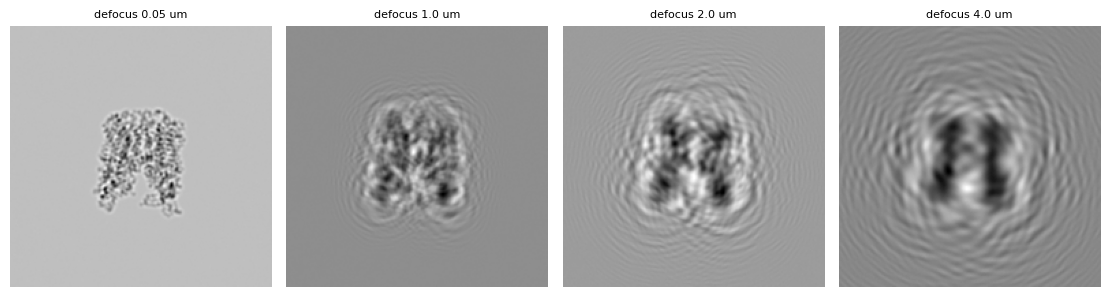

In [16]:
defoci = [0.05, 1.0, 2.0, 4.0]
show(variants(k, [{**quiet, "cl_present": 0.0, "b_factor": 10.0, "defocus": d} for d in defoci]),
     [f"defocus {d} um" for d in defoci], cols=4, size=2.8)

## 1.9 The signal-to-noise ratio

`log10_snr` sets how much noise is added: the noise variance is the variance of the blurred molecule divided by the SNR. Below: the same image with clutter off, at five SNRs. Experimental particle images sit at the right-hand end of this row.

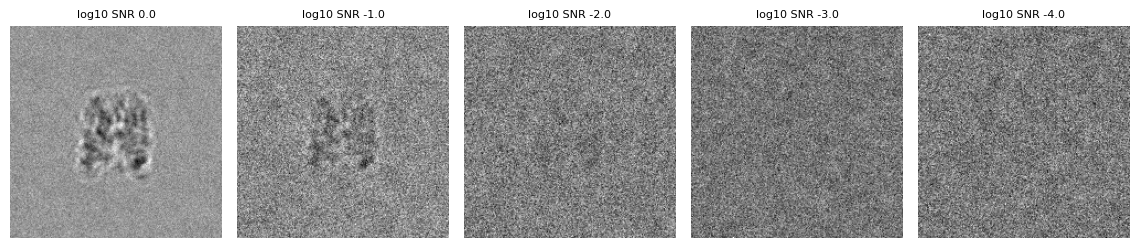

In [17]:
snrs = [0.0, -1.0, -2.0, -3.0, -4.0]
show(variants(k, [{"cl_present": 0.0, "log10_snr": s} for s in snrs]), [f"log10 SNR {s}" for s in snrs])

## 1.10 Part 1 in five lines

```python
bank   = v3.load_bank("data/pdb")                                # the molecule
shape  = v3.RenderShape(num_pixels=192, pixel_size=1.345)        # the box
phi    = v3.pack_phi(v3.DEFAULT_PRIOR)                           # the prior
theta  = v3.sample_theta(phi, 10, seed=0, bank=bank, cfg=shape)  # the settings of 10 images
images = v3.render(theta, bank, shape)                           # the images
```

`example.py` does the same with the conformer bank and the measured noise spectrum of Part 2.

---
# Part 2 — Closer to an experimental data set

Part 1 used one structure, an average noise spectrum and the default prior. Part 2 replaces each of them in turn.

## 2.1 Several conformations: a conformer bank

A flexible molecule takes several shapes. A bank can hold several conformers, and each image draws one of them at random, all with the same probability. There are two ways to build a bank:

* put several PDB files in one folder and call `v3.load_bank(folder)`: one conformer per file, read in alphabetical order. Files with fewer selected atoms are padded, so the conformers do not need the same number of beads;
* load a bank saved earlier with `torch.save`, using `v3.load_bank_pt(file)`.

`data/trpv1_bank.pt` holds four TRPV1 conformers saved that way. To see them clearly, we render ten images with the noise, the clutter and the edge band switched off, set rotation and set defocus.

bank: (4, 1, 3, 2694)


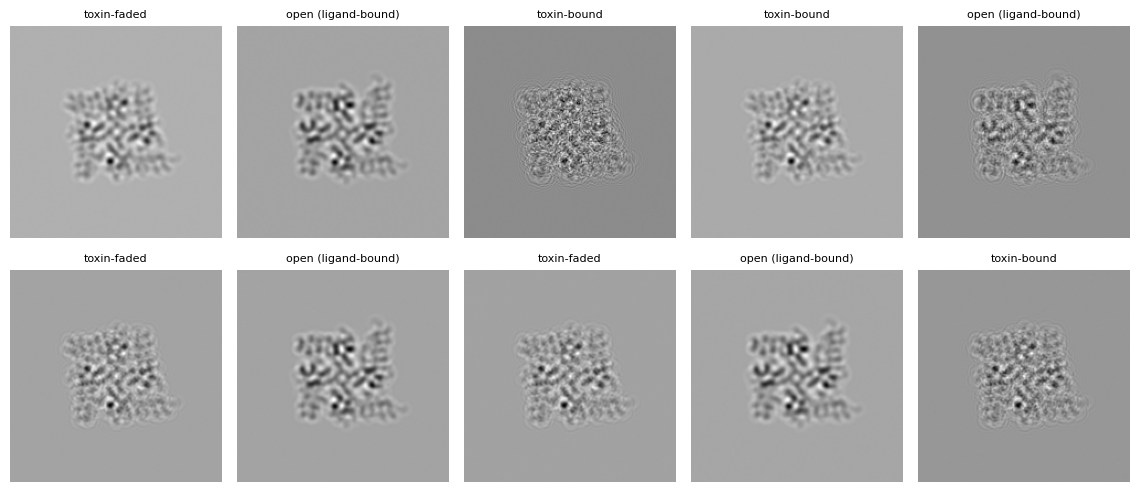

In [25]:
bank4 = v3.load_bank_pt("data/trpv1_bank.pt", device=device)
names = ["toxin-bound", "toxin-faded", "closed (apo-like)", "open (ligand-bound)"]
print("bank:", tuple(bank4.shape))

theta4 = v3.sample_theta(phi, 10, seed=1, bank=bank4, cfg=shape)
g = v3.unpack_theta(theta4.clone())
g["log10_snr"][:] = 3.0           # noise almost off
g["cl_present"][:] = 0.0          # no clutter
g["band_present"][:] = 0.0        # no edge band
g["defocus"][:] = 0.3             # set defocus
g["quaternion"][:] = 0.0          # no rotation
f4 = v3.unpack_theta(theta4)
show(v3.render(v3.pack_theta(g), bank4, shape), [names[int(c)] for c in f4["conformer_idx"][:, 0]])

## 2.2 The noise spectrum of an experimental data set

The noise in experimental particle images is not white: the ice, the detector and the microscope give it more power at some spatial scales than at others. Part of v3's noise, the **coloured noise**, is shaped with the average 2-D power spectrum of experimental particles from the data set you want.

`data/trpv1_particles/` holds 100 experimental particles from EMPIAR-10059 (`SOURCE.txt` lists where each one comes from). We use them only for their power spectrum, which does not depend on the sign of the image contrast.

**For your own data set:** put its particle stacks (`.mrc` or `.mrcs`) in one folder, set `PARTICLES` to it, and give `RenderShape` the same box size and pixel size as the particles. The pixel size is not read from the files. More particles give a smoother spectrum; without `num_images`, 10 000 are used.

100 experimental particles found


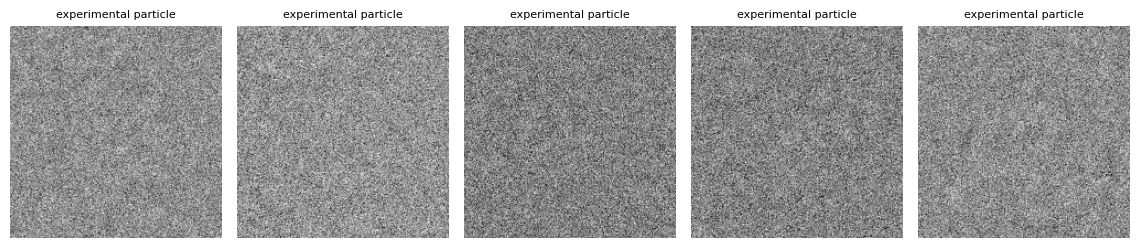

In [26]:
PARTICLES = "data/trpv1_particles"
BOX, PIXEL_SIZE = 192, 1.345              # pixels; Angstrom per pixel: those of the particles
SPECTRUM_FILE = "data/trpv1_psd.pt"

index = v3.build_image_index(PARTICLES)   # every image: (file, position in its stack)
print(f"{len(index)} experimental particles found")
show(v3.load_image_batch(index[:5]), ["experimental particle"] * 5)

{'mean_psd': (192, 192), 'radial_psd': (136,), 'estimated_alpha': 2.0273187160491943, 'num_images_used': 100, 'selection_mode': 'random', 'root_folder': 'data/trpv1_particles'}


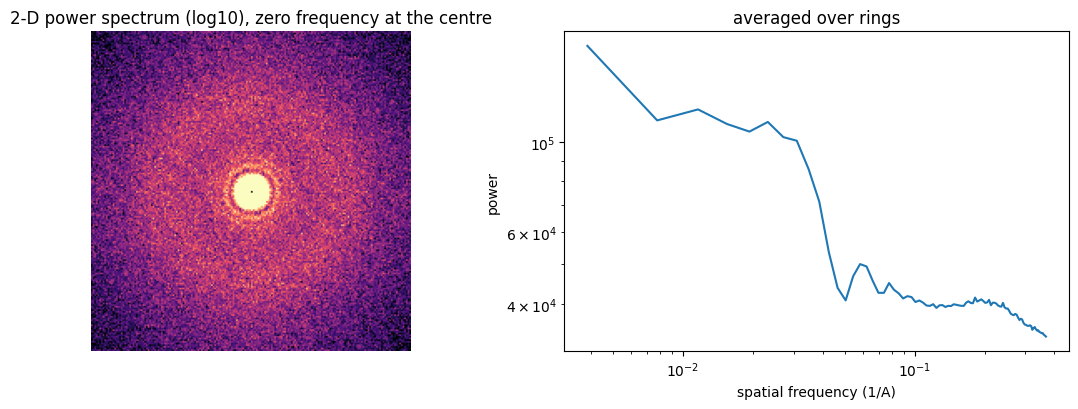

In [27]:
stats = v3.estimate_empirical_noise_parameters(PARTICLES, num_images=100)
torch.save(stats, SPECTRUM_FILE)          # the renderer reads this file
print({k: tuple(v.shape) if torch.is_tensor(v) else v for k, v in stats.items()})

half = BOX // 2                           # rings up to the highest frequency the pixels hold
freq = torch.arange(half) / (BOX * PIXEL_SIZE)
spec = torch.fft.fftshift(stats["mean_psd"]).clamp_min(1e-12).log10()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].imshow(spec, cmap="magma", vmin=spec.quantile(0.01).item(), vmax=spec.quantile(0.99).item())
ax[0].set_title("2-D power spectrum (log10), zero frequency at the centre"); ax[0].axis("off")
ax[1].loglog(freq[1:], stats["radial_psd"][1:half])
ax[1].set_xlabel("spatial frequency (1/A)"); ax[1].set_ylabel("power"); ax[1].set_title("averaged over rings")
plt.tight_layout(); plt.show()

Now give the spectrum file to `RenderShape`. The difference is hard to see in single images, so we compare power spectra instead: 200 images rendered from the same θ, once with the average spectrum of Part 1 and once with the TRPV1 spectrum, against the experimental particles. Every image is first scaled to mean 0 and standard deviation 1, so that only the shape of the spectra is compared.

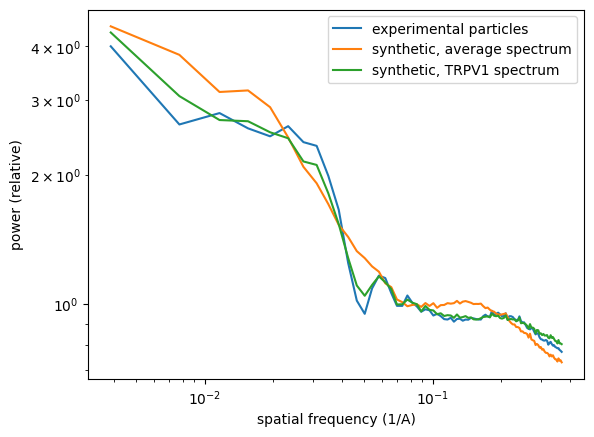

In [28]:
shape_trpv1 = v3.RenderShape(num_pixels=BOX, pixel_size=PIXEL_SIZE, noise={"empirical_cache_file": SPECTRUM_FILE})
theta200 = v3.sample_theta(phi, 200, seed=5, bank=bank, cfg=shape)


def ring_spectrum(stack):
    """Average power spectrum over rings, of images scaled to mean 0 and standard deviation 1."""
    x = stack.float().cpu()
    x = (x - x.mean((-2, -1), keepdim=True)) / x.std((-2, -1), keepdim=True)
    r = v3.radial_power_spectrum(v3.power_spectrum(x)).mean(0)[:half]
    return r / r[5:].mean()


curves = {"experimental particles": ring_spectrum(v3.load_image_batch(index)),
          "synthetic, average spectrum": ring_spectrum(v3.render(theta200, bank, shape)),
          "synthetic, TRPV1 spectrum": ring_spectrum(v3.render(theta200, bank, shape_trpv1))}
for label, c in curves.items():
    plt.loglog(freq[1:], c[1:], label=label)
plt.xlabel("spatial frequency (1/A)"); plt.ylabel("power (relative)"); plt.legend(); plt.show()

With the TRPV1 spectrum, the synthetic images follow the experimental curve more closely, including its dip and bump around 0.05 Å⁻¹. (Here the spectrum was measured on the same 100 particles it is compared with; with your own data, measure it on as many particles as you can.)

Instead of a file, `RenderShape` also accepts the folder itself, `noise={"empirical_root_folder": PARTICLES}`; the spectrum is then measured the first time an image is rendered.

## 2.3 A prior of your own

To change the prior, copy the default dictionary, change entries, and pack it again. As an example, a cleaner data set: higher SNR, no clutter, no edge bands. Keep to the rules: ranges must have `lo < hi`, noise weights stay between 0 and 1, probabilities between 0 and 1; `count_probs` and `side_weights` are divided by their sums.

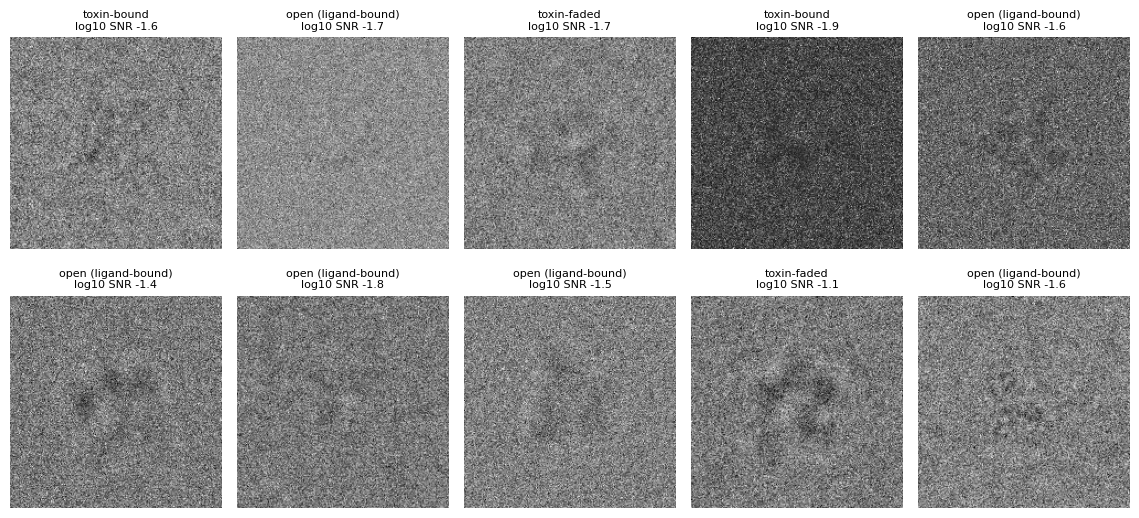

In [29]:
my_prior = copy.deepcopy(v3.DEFAULT_PRIOR)
my_prior["SNR"] = [-2.0, -1.0]                 # log10 SNR between -2 and -1
my_prior["count_probs"] = [1, 0, 0, 0, 0, 0]   # always 0 clutter objects
my_prior["barcode_prob"] = 0.0                 # never an edge band

theta_mine = v3.sample_theta(v3.pack_phi(my_prior, device=device), 10, seed=0, bank=bank4, cfg=shape_trpv1)
f_mine = v3.unpack_theta(theta_mine)
show(v3.render(theta_mine, bank4, shape_trpv1),
     [f"{names[int(c)]}\nlog10 SNR {s:.1f}" for c, s in zip(f_mine["conformer_idx"][:, 0], f_mine["log10_snr"].tolist())])

## Where to go next

* `example.py`: the shortest complete script.
* `README.md`: how each stage works, all entries of φ and θ, and the known simplifications.
* `v3_core.py`: every function is documented; `help(v3.render)` prints any of them.